# Native DINO: one-seed adaptation and health pilot

**Complete** — 672/672 minibatches. Updated 2026-11-18T21:00:01.846922+01:00.

Completed trained policies: 3/3. ETA: **2026-11-18T21:00:01.846904+01:00** (Stockholm).

One seed; frozen reference, Full, Late4, and runtime-credit periodic Full. The exact E203 repeated-shift stream, image reservations and no-replay setup are reused.

Native E202A recipe: LR9e-5, layer decay0.75, AdamW0.05, clipping1, two224px global crops and ten96px local crops; teacher temperature0.07, student0.1, center momentum0.9, EMA base0.996. Both complete pretrained heads and encoders are restored.

EMA advances only on enabled updates; its cosine horizon is672 arrivals. A skipped batch freezes student, teacher, center, optimizer and EMA clock. Periodic training therefore ends earlier on the same update-clock ramp. Frozen early student layers can still have teacher EMA drift toward their fixed student values.

Teacher representations are primary; student results are separate. Two independent128-image banks, eight views at regime boundaries, lighter two-view reads after shifts. Five external linear tasks and scene kNN use frozen reservations. Labels only enter these offline evaluations.

Primary scope: fixed-policy frontier and exploratory health–utility alignment. One seed cannot establish replication. Counterfactual or EMA-action expansion is not launched automatically. Shared-GPU timing is provisional; the existing Windows E203 run is not sharing its GPU.

Summary and saved figures are in results/.


In [ ]:
from pathlib import Path
import json
r=Path('/home/edgelab/cafl-dino-pilot/results')
display(json.loads((r/'status.json').read_text()))


## One-seed screening results

Teacher is the primary deployment representation. Gains below are percentage points against its own frozen initialization.

| Policy | Scene | Weather | Lighting | Traffic light | Pedestrian | Scene kNN |
|---|---:|---:|---:|---:|---:|---:|
| frozen | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 |
| full | +2.41 | +0.27 | +0.85 | +1.40 | -1.93 | +1.76 |
| late4 | +0.73 | -1.38 | +0.43 | +1.01 | -2.34 | -0.47 |
| periodic | +2.24 | +0.09 | +0.48 | +1.95 | -2.72 | -0.47 |

Within-policy level, change and change-per-minibatch correlations are exploratory. The rate analysis accounts for unequal8/88/96-batch readout intervals. Sparse within-regime cells and constant frozen curves have no reported correlation. One seed provides no independent replication or held-out-seed validation.

No counterfactual, EMA-action, predictor or MPC expansion was automatically run. Shared-GPU runtime matching remains provisional.

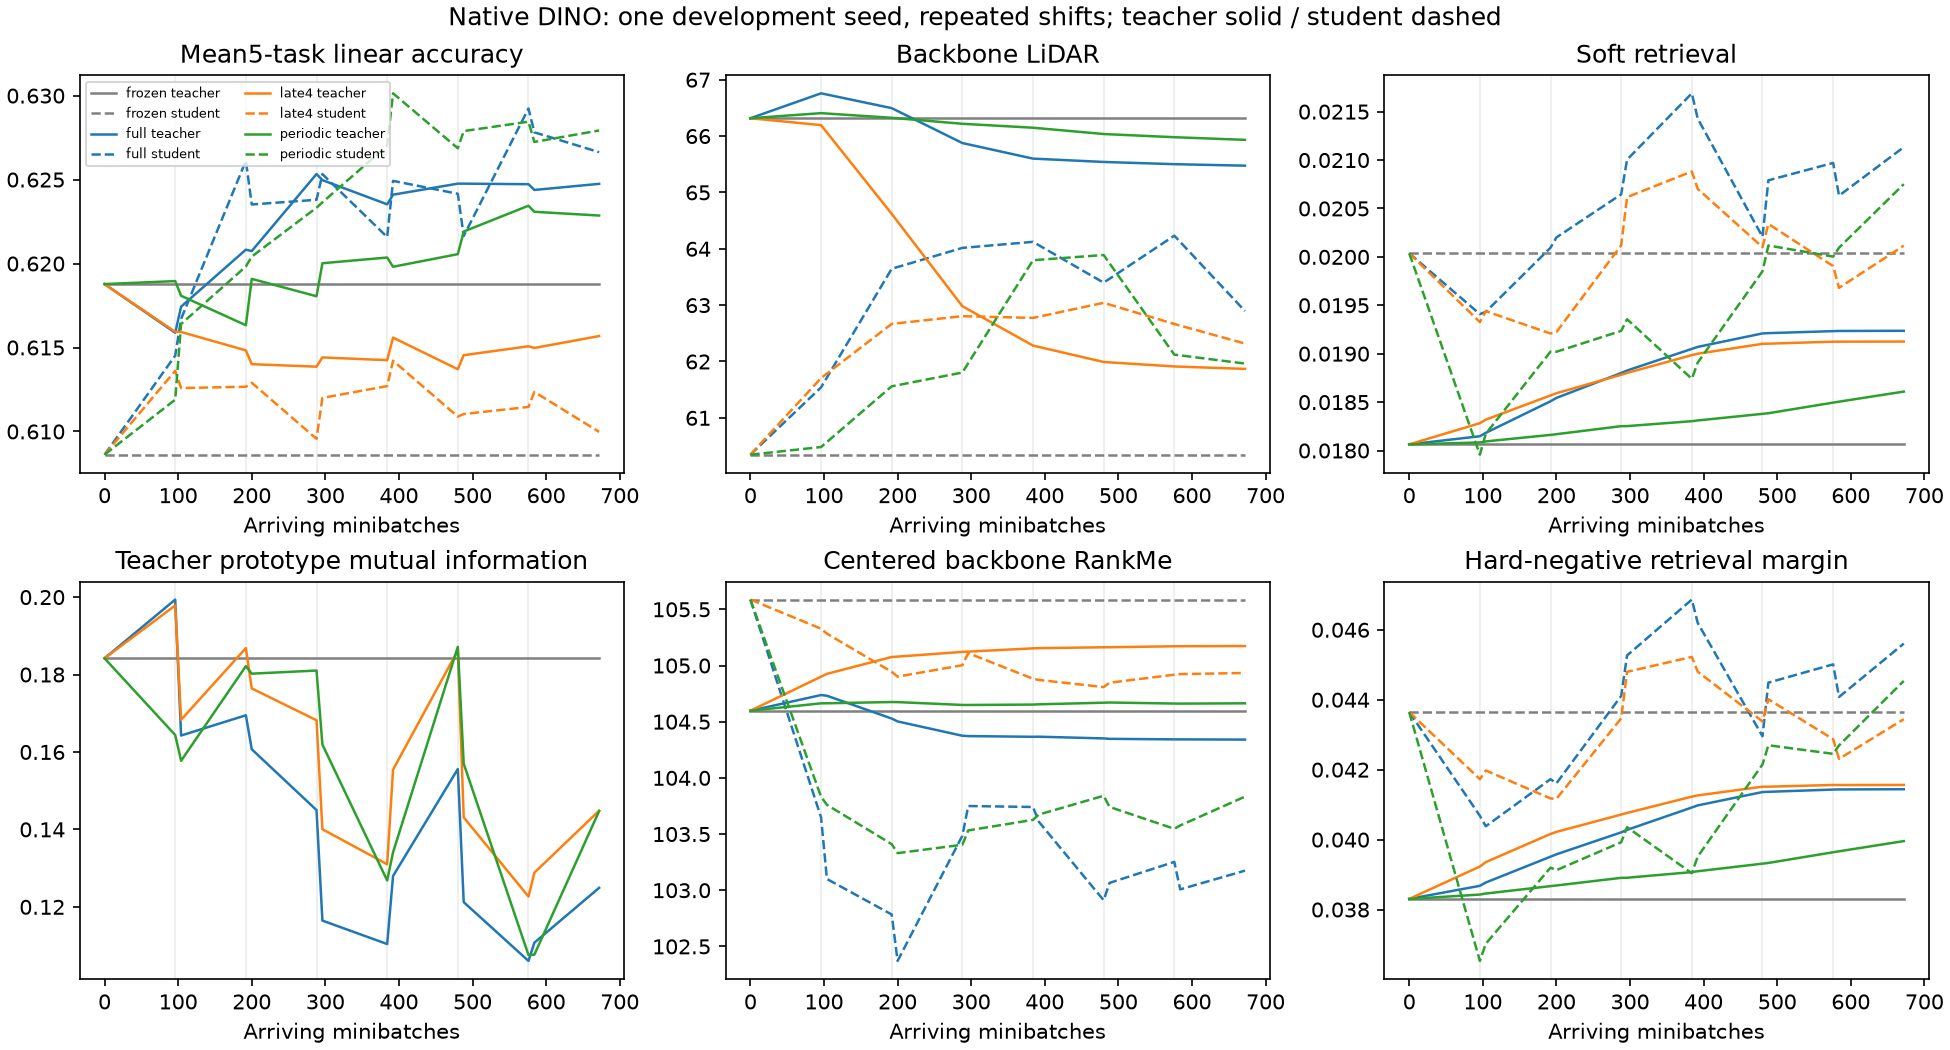

In [ ]:
# Saved result figure